# Indian Flight Fare Analysis and Prediction

**Objective:** Regression-focused Exploratory Data Analysis (EDA) to understand how airline, route, stops, duration,
departure time, class and booking window (days left) influence flight ticket prices in India.

**How to use this notebook:** Upload `Clean_Dataset.csv` (Kaggle - Flight Price Prediction) to Colab, run all cells
top to bottom, and write your own observation under every **Insight** line.

In [1]:
'''
Indian Flight Fare Analysis and Prediction
------------------------------------------
Author: Parth Dixit
Description: End-to-end EDA notebook pipeline for flight fare data processing.
'''
import pandas as pd  #FOR DATA MANIPULATION, PROCESSING METHODS
import numpy as np   #FOR NUMERICAL CALCULATIONS ON DATA
import matplotlib.pyplot as plt  #FOR DATA VISUALIZATION FOR ANALYSIS
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')

# Global plot formatting configuration
try:
    plt.style.use('seaborn-v0_8-whitegrid') #SETTING UP DEFAULT VISUALIZATION FORMAT 
except Exception:
    plt.style.use('seaborn-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans' #FONT TYPE
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
pd.set_option('display.max_columns', 50)

## Section A - Data acquisition, inspection and preprocessing

Load the dataset; first 10 and last 10 records

In [2]:
# In Colab: left sidebar > Files > Upload, or use: from google.colab import files; files.upload()
DATA_PATH = '/kaggle/input/datasets/shubhambathwal/flight-price-prediction/Clean_Dataset.csv'
df = pd.read_csv(DATA_PATH)

# Standardise column names (drop the unnamed index column, lowercase, underscores)
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]
df.columns = [c.strip().lower().replace(' ', '_') for c in df.columns]
df = df.rename(columns={'class': 'travel_class'})

display(df.head(10))
display(df.tail(10))

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,travel_class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
5,Vistara,UK-945,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.33,1,5955
6,Vistara,UK-927,Delhi,Morning,zero,Morning,Mumbai,Economy,2.08,1,6060
7,Vistara,UK-951,Delhi,Afternoon,zero,Evening,Mumbai,Economy,2.17,1,6060
8,GO_FIRST,G8-334,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.17,1,5954
9,GO_FIRST,G8-336,Delhi,Afternoon,zero,Evening,Mumbai,Economy,2.25,1,5954


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,travel_class,duration,days_left,price
300143,Air_India,AI-440,Chennai,Early_Morning,one,Night,Hyderabad,Business,17.42,49,51345
300144,Air_India,AI-539,Chennai,Evening,one,Morning,Hyderabad,Business,18.92,49,51345
300145,Air_India,AI-430,Chennai,Morning,one,Morning,Hyderabad,Business,23.08,49,51345
300146,Air_India,AI-440,Chennai,Early_Morning,one,Morning,Hyderabad,Business,26.83,49,51345
300147,Air_India,AI-569,Chennai,Early_Morning,one,Night,Hyderabad,Business,17.25,49,68739
300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585
300152,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,81585


**Insight:** The dataset has 300,153 flight ticket records and 11 columns. The first rows are Delhi-to-Mumbai flights booked 1 day before departure.

### Number of rows and columns - Shape of Dataframe = Rows X Columns

In [3]:
print('Rows   :', df.shape[0])
print('Columns:', df.shape[1])

Rows   : 300153
Columns: 11


**Insight:** The data has 300,153 rows and 11 columns. One row is one flight ticket (booking option) for a given airline, route, class and number of days left before departure.

### Column names, dtypes, non-null counts (info) - numerical, categorical, temporal

In [4]:
df.info()
num_cols = df.select_dtypes(include='number').columns.tolist() #NUMERICAL COLUMNS
cat_cols = df.select_dtypes(exclude='number').columns.tolist() #CATEGORICAL COLUMNS
temporal_cols = [c for c in ['departure_time', 'arrival_time', 'days_left', 'duration'] if c in df.columns]
print('\nNumerical  :', num_cols)
print('Categorical:', cat_cols)
print('Temporal   :', temporal_cols, '(time-of-day buckets, hours of travel and days before departure)')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  object 
 1   flight            300153 non-null  object 
 2   source_city       300153 non-null  object 
 3   departure_time    300153 non-null  object 
 4   stops             300153 non-null  object 
 5   arrival_time      300153 non-null  object 
 6   destination_city  300153 non-null  object 
 7   travel_class      300153 non-null  object 
 8   duration          300153 non-null  float64
 9   days_left         300153 non-null  int64  
 10  price             300153 non-null  int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 25.2+ MB

Numerical  : ['duration', 'days_left', 'price']
Categorical: ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'travel_class']
Temporal   : ['departure

**Insight:** No column has missing values (300,153 non-null everywhere). There are 3 numerical columns (duration, days_left, price) and 8 categorical columns (airline, flight, source_city, destination_city, stops, class and the two time buckets). Time is stored as buckets (departure_time, arrival_time) plus duration and days_left rather than raw timestamps.

### Memory consumption and reducing it

In [ ]:
mem_before = df.memory_usage(deep=True).sum() / 1024**2
df_opt = df.copy()
for c in df_opt.select_dtypes(include='object').columns:
    df_opt[c] = df_opt[c].astype('category')                 #CHOOSING OBJECT COLUMNS AND CONVERTING IT TO CATEGORY

#CHOOSING INTEGER COLUMNS AND CONVERTING IT TO SMALL DATATYPE THAT CONSUMES LESS MEMORY
for c in df_opt.select_dtypes(include='integer').columns:
    df_opt[c] = pd.to_numeric(df_opt[c], downcast='integer')
for c in df_opt.select_dtypes(include='float').columns:
    df_opt[c] = pd.to_numeric(df_opt[c], downcast='float')
mem_after = df_opt.memory_usage(deep=True).sum() / 1024**2

print(f'Memory before: {mem_before:.2f} MB')
print(f'Memory after : {mem_after:.2f} MB  ({(1 - mem_after / mem_before) * 100:.1f}% reduction)')
# NOTE: we keep working on the original df to keep later groupby code simple.

**Insight:** Converting object columns to category and downcasting numbers reduced memory from 134.5 MB to 5.3 MB (about 96% less), which makes processing faster.

Unique values per column; high-cardinality columns

In [5]:
uniq = df.nunique().sort_values(ascending=False) #DISPLAY WHICH COLUMNS HAVE MORE UNIQUE VALUES IN DESCENDING ORDER
display(uniq.to_frame('unique_values'))
high_card = uniq[uniq > 50].index.tolist()
print('High-cardinality columns (>50 unique):', high_card)

,unique_values
price,12157
flight,1561
duration,476
days_left,49
airline,6
source_city,6
departure_time,6
arrival_time,6
destination_city,6
stops,3


High-cardinality columns (>50 unique): ['price', 'flight', 'duration']


**Insight:** price (12,157), flight (1,561) and duration (476) are high-cardinality columns. The flight code behaves like an identifier, so it is not used for modelling. Airline, cities, class, stops and time buckets have only 2 to 6 unique values.

### Missing values (count and percentage)

In [6]:
missing = pd.DataFrame({'missing_count': df.isnull().sum(),  #GIVES TOTAL NULL VALUES FOR EVERY COLUMNS
                        'missing_pct': df.isnull().mean() * 100})
display(missing)

,missing_count,missing_pct
airline,0,0.00
flight,0,0.00
source_city,0,0.00
departure_time,0,0.00
stops,0,0.00
arrival_time,0,0.00
destination_city,0,0.00
travel_class,0,0.00
duration,0,0.00
days_left,0,0.00


As you can see no columns have null values

### checking Duplicate rows - if they exists they will be removed by user permission

In [8]:
dup_count = df.duplicated().sum()
print('Duplicate rows:', dup_count)
if dup_count > 0:
    display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10))

Duplicate rows: 0


**Insight:** There are no duplicate rows (0), so nothing needed to be removed. Even when duplicates exist they should not be dropped blindly, because identical rows can be genuinely different tickets in sampled booking data.

### Inconsistent categorical values (spaces, capitalisation, spelling)

In [9]:
obj_cols = df.select_dtypes(exclude='number').columns
for c in obj_cols:
    raw = df[c].nunique()
    clean = df[c].astype(str).str.strip().str.lower().nunique()
    print(f'{c:18s} raw unique = {raw:5d} | after strip+lower = {clean:5d}')

# Clean anyway (safe)
for c in obj_cols:
    df[c] = df[c].astype(str).str.strip()

for c in ['airline', 'source_city', 'destination_city', 'travel_class', 'stops', 'departure_time', 'arrival_time']:
    if c in df.columns:
        print(f'\n{c}:', sorted(df[c].unique()))

airline            raw unique =     6 | after strip+lower =     6
flight             raw unique =  1561 | after strip+lower =  1561
source_city        raw unique =     6 | after strip+lower =     6
departure_time     raw unique =     6 | after strip+lower =     6
stops              raw unique =     3 | after strip+lower =     3
arrival_time       raw unique =     6 | after strip+lower =     6
destination_city   raw unique =     6 | after strip+lower =     6
travel_class       raw unique =     2 | after strip+lower =     2

airline: ['AirAsia', 'Air_India', 'GO_FIRST', 'Indigo', 'SpiceJet', 'Vistara']

source_city: ['Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Kolkata', 'Mumbai']

destination_city: ['Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Kolkata', 'Mumbai']

travel_class: ['Business', 'Economy']

stops: ['one', 'two_or_more', 'zero']

departure_time: ['Afternoon', 'Early_Morning', 'Evening', 'Late_Night', 'Morning', 'Night']

arrival_time: ['Afternoon', 'Early_Morning', 'Eveni

**Insight:** Stripping spaces and lower-casing did not change the number of unique values in any column, so the categories are consistent (6 airlines, 6 cities, 2 classes, 3 stop types).

### Examine the Price column - zero, negative, unusually low/high

In [10]:
p = df['price']
print('Zero prices    :', (p == 0).sum())
print('Negative prices:', (p < 0).sum())
print('Min / Max      :', p.min(), '/', p.max())
print('\n5 lowest :', p.nsmallest(5).tolist())
print('5 highest:', p.nlargest(5).tolist())
display(df.groupby('travel_class')['price'].describe())

Zero prices    : 0
Negative prices: 0
Min / Max      : 1105 / 123071

5 lowest : [1105, 1105, 1105, 1105, 1105]
5 highest: [123071, 117307, 116562, 115211, 114705]


,count,mean,std,min,25%,50%,75%,max
travel_class,,,,,,,,
Business,"93,487.00","52,540.08","12,969.31","12,000.00","45,185.00","53,164.00","60,396.00","123,071.00"
Economy,"206,666.00","6,572.34","3,743.52","1,105.00","4,173.00","5,772.00","7,746.00","42,349.00"


**Insight:** There are no zero or negative prices. Prices range from Rs 1,105 to Rs 1,23,071. The highest fares are Business class (Business max Rs 1,23,071 vs Economy max Rs 42,349), so they are genuine premium fares and not errors. The Business median is Rs 53,164 compared with Rs 5,772 for Economy.

### Data dictionary

In [11]:
meaning = {
    'airline': 'Name of the airline operating the flight',
    'flight': 'Flight code',
    'source_city': 'City of departure',
    'departure_time': 'Departure time bucket (Early Morning...Late Night)',
    'stops': 'Number of stops (zero / one / two_or_more)',
    'arrival_time': 'Arrival time bucket',
    'destination_city': 'City of arrival',
    'travel_class': 'Economy or Business',
    'duration': 'Total travel time in hours',
    'days_left': 'Days between booking date and departure date',
    'price': 'Ticket price in INR (target variable)'
}
prep = {
    'airline': 'Strip spaces; one-hot / label encode',
    'flight': 'High cardinality; usually drop or target-encode',
    'source_city': 'One-hot encode', 'destination_city': 'One-hot encode',
    'departure_time': 'Ordinal / cyclical time-of-day feature', 'arrival_time': 'Ordinal / cyclical time-of-day feature',
    'stops': 'Ordinal encode (0, 1, 2+)', 'travel_class': 'Binary encode',
    'duration': 'Numeric; check skew', 'days_left': 'Numeric; bin into booking windows',
    'price': 'Target; check skew, consider log transform'
}
dd = pd.DataFrame({'feature': df.columns,
                   'dtype': [str(df[c].dtype) for c in df.columns],
                   'meaning': [meaning.get(c, '-') for c in df.columns],
                   'preprocessing': [prep.get(c, '-') for c in df.columns]})
display(dd)

,feature,dtype,meaning,preprocessing
0,airline,object,Name of the airline operating the flight,Strip spaces; one-hot / label encode
1,flight,object,Flight code,High cardinality; usually drop or target-encode
2,source_city,object,City of departure,One-hot encode
3,departure_time,object,Departure time bucket (Early Morning...Late Ni...,Ordinal / cyclical time-of-day feature
4,stops,object,Number of stops (zero / one / two_or_more),"Ordinal encode (0, 1, 2+)"
5,arrival_time,object,Arrival time bucket,Ordinal / cyclical time-of-day feature
6,destination_city,object,City of arrival,One-hot encode
7,travel_class,object,Economy or Business,Binary encode
8,duration,float64,Total travel time in hours,Numeric; check skew
9,days_left,int64,Days between booking date and departure date,Numeric; bin into booking windows


**Insight:** The data dictionary lists the type, meaning and preprocessing for each feature. Price is the target variable, the flight code is dropped because of high cardinality, and the categorical columns need encoding before modelling.

## Section B - Univariate analysis: understanding flight prices

### Mean, median, mode, std, variance, min, max of Price

In [12]:
p = df['price']
stats = pd.Series({'mean': p.mean(), 'median': p.median(), 'mode': p.mode().iloc[0],
                   'std': p.std(), 'variance': p.var(), 'min': p.min(), 'max': p.max()})
display(stats.to_frame('price'))

,price
mean,"20,889.66"
median,"7,425.00"
mode,"54,608.00"
std,"22,697.77"
variance,"515,188,643.40"
min,"1,105.00"
max,"123,071.00"


**Insight:** The mean (Rs 20,890) is much higher than the median (Rs 7,425), so the prices are right-skewed. The mode (Rs 54,608) lies in the Business range, and the large standard deviation (Rs 22,698) shows a wide spread caused by mixing two very different classes.

### Histogram + KDE - normal, positively or negatively skewed?

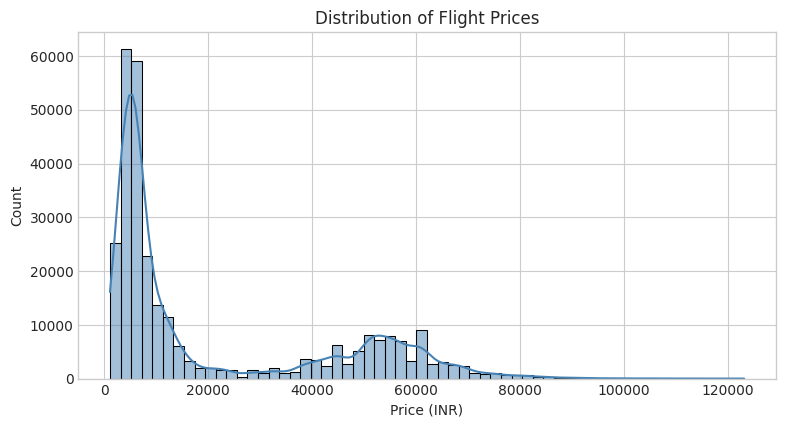

Skewness: 1.061


In [13]:
plt.figure(figsize=(9, 4.5))
sns.histplot(df['price'], bins=60, kde=True, color='steelblue')
plt.title('Distribution of Flight Prices'); plt.xlabel('Price (INR)')
plt.show()
print('Skewness:', round(df['price'].skew(), 3))

**Insight:** The distribution is positively (right) skewed with skewness 1.06. It has a long tail of expensive tickets and a second hump from Business class, so it is clearly not normal.

### Boxplot of Price + outliers using the IQR method

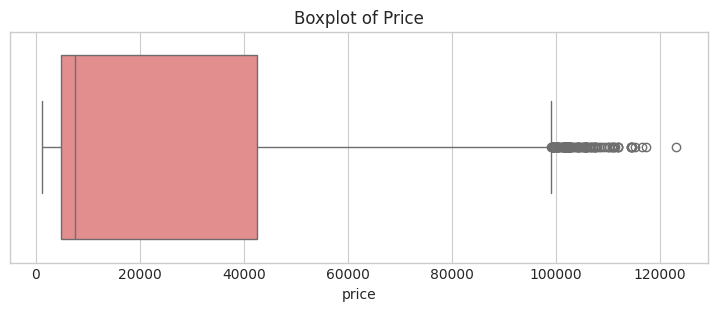

Q1=4,783  Q3=42,521  IQR=37,738  Lower=-51,824  Upper=99,128
Outliers: 123 (0.04%)
travel_class
Business    123
Name: count, dtype: int64


In [14]:
plt.figure(figsize=(9, 3))
sns.boxplot(x=df['price'], color='lightcoral')
plt.title('Boxplot of Price'); plt.show()

q1, q3 = p.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(p < lower) | (p > upper)]
print(f'Q1={q1:,.0f}  Q3={q3:,.0f}  IQR={iqr:,.0f}  Lower={lower:,.0f}  Upper={upper:,.0f}')
print(f'Outliers: {len(outliers):,} ({len(outliers) / len(df) * 100:.2f}%)')
print(outliers['travel_class'].value_counts())

**Insight:** With the IQR method (upper limit Rs 99,128) only 123 tickets (0.04%) are outliers and all of them are Business class. They are genuine high fares, so they should be kept.

### Percentiles: 5th, 25th, 50th, 75th, 90th, 95th, 99th

In [15]:
display(df['price'].quantile([0.05, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99]).to_frame('price'))

,price
0.05,"2,436.00"
0.25,"4,783.00"
0.50,"7,425.00"
0.75,"42,521.00"
0.90,"57,920.00"
0.95,"63,277.00"
0.99,"76,736.00"


**Insight:** The median fare is Rs 7,425 but the 75th percentile jumps to Rs 42,521. This jump shows that roughly the top 30% of tickets are Business fares. The 99th percentile is Rs 76,736.

### Percentage of tickets below Rs 3,000 / 5,000 / 10,000 / 20,000

In [16]:
for t in [3000, 5000, 10000, 20000, 50000]:
    print(f'Price < Rs {t:>6,}: {(df.price < t).mean() * 100:6.2f}%')
print('\nAdjusted (data-driven) thresholds using percentiles:')
for q in [0.25, 0.50, 0.75, 0.90]:
    print(f'  {int(q*100)}th percentile = Rs {df.price.quantile(q):,.0f}')

Price < Rs  3,000:   7.26%
Price < Rs  5,000:  27.11%
Price < Rs 10,000:  57.85%
Price < Rs 20,000:  68.38%
Price < Rs 50,000:  80.22%

Adjusted (data-driven) thresholds using percentiles:
  25th percentile = Rs 4,783
  50th percentile = Rs 7,425
  75th percentile = Rs 42,521
  90th percentile = Rs 57,920


**Insight:** About 7.3% of tickets cost less than Rs 3,000, 27.1% less than Rs 5,000, 57.9% less than Rs 10,000 and 68.4% less than Rs 20,000. Only about 20% cost more than Rs 50,000.

### Frequency distribution of airlines

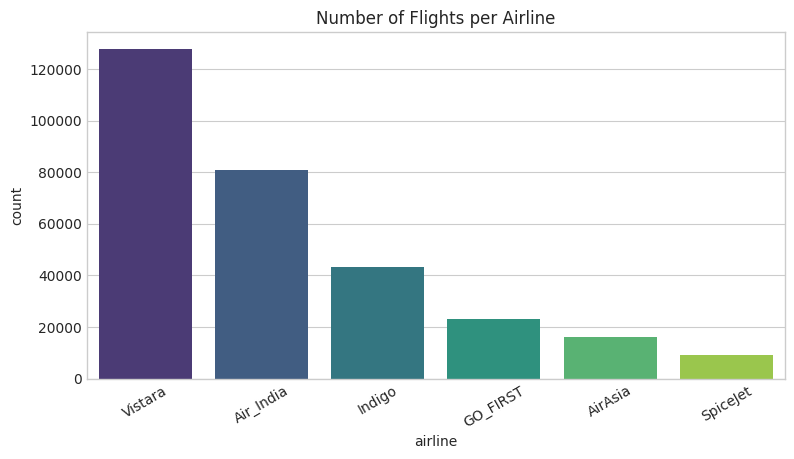

,count
airline,
Vistara,127859
Air_India,80892
Indigo,43120
GO_FIRST,23173
AirAsia,16098
SpiceJet,9011


In [17]:
plt.figure(figsize=(9, 4.5))
order = df['airline'].value_counts().index
sns.countplot(data=df, x='airline', order=order, palette='viridis')
plt.title('Number of Flights per Airline'); plt.xticks(rotation=30); plt.show()
display(df['airline'].value_counts().to_frame('count'))

**Insight:** Vistara has the most tickets (127,859), followed by Air India (80,892) and Indigo (43,120). SpiceJet has the fewest (9,011).

### Frequency of source and destination cities - equally represented?

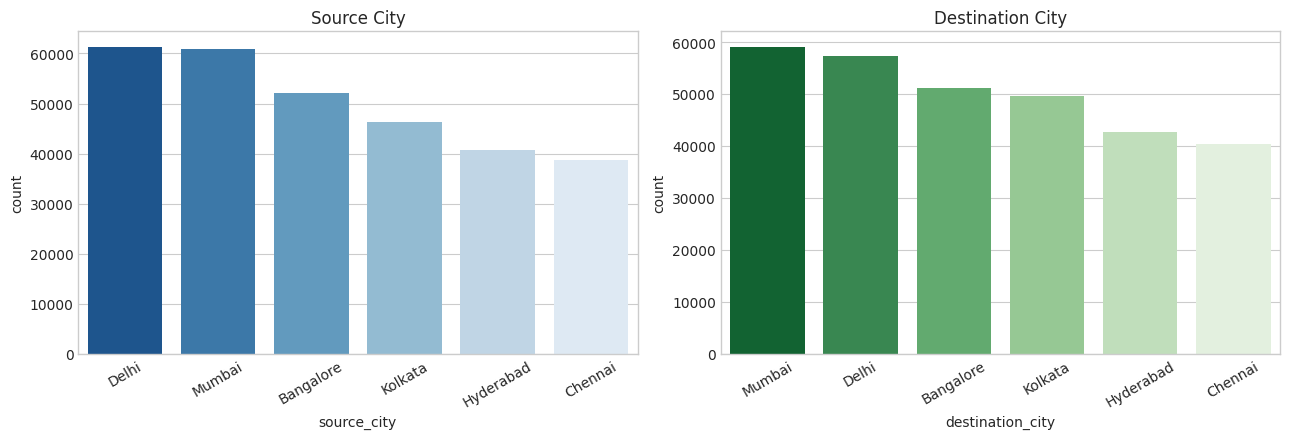

source_city
Delhi       20.44
Mumbai      20.29
Bangalore   17.34
Kolkata     15.44
Hyderabad   13.60
Chennai     12.89
Name: proportion, dtype: float64


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x='source_city', order=df['source_city'].value_counts().index, ax=ax[0], palette='Blues_r')
ax[0].set_title('Source City'); ax[0].tick_params(axis='x', rotation=30)
sns.countplot(data=df, x='destination_city', order=df['destination_city'].value_counts().index, ax=ax[1], palette='Greens_r')
ax[1].set_title('Destination City'); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
print((df['source_city'].value_counts(normalize=True) * 100).round(2))

**Insight:** Cities are not equally represented. Delhi (20.4%) and Mumbai (20.3%) are the most common source cities, while Chennai (12.9%) is the least common.

### Distribution of Stops (non-stop / one-stop / multi-stop %)

,percent
stops,
one,83.58
zero,12.00
two_or_more,4.43


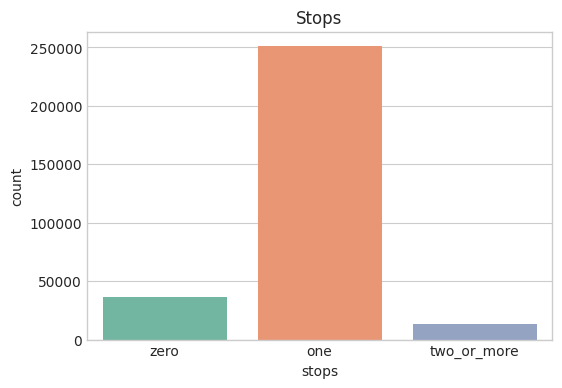

In [19]:
stops_pct = df['stops'].value_counts(normalize=True) * 100
display(stops_pct.round(2).to_frame('percent'))
plt.figure(figsize=(6, 4)); sns.countplot(data=df, x='stops', palette='Set2'); plt.title('Stops'); plt.show()

**Insight:** Most flights are one-stop (83.6%). Non-stop flights are only 12.0% and flights with two or more stops are 4.4%.

### Duration: shortest, longest, median, average

Shortest: 0.83 h | Longest: 49.83 h | Median: 11.25 h | Mean: 12.22 h


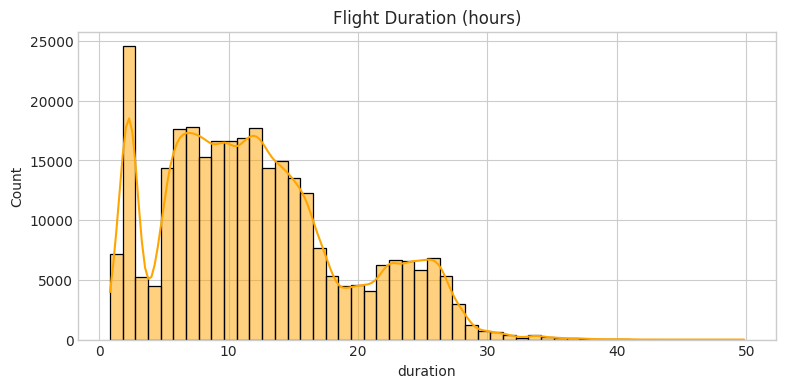

In [20]:
d = df['duration']
print(f'Shortest: {d.min():.2f} h | Longest: {d.max():.2f} h | Median: {d.median():.2f} h | Mean: {d.mean():.2f} h')
plt.figure(figsize=(9, 4)); sns.histplot(d, bins=50, kde=True, color='orange'); plt.title('Flight Duration (hours)'); plt.show()

**Insight:** Flight duration ranges from 0.83 hours to 49.83 hours, with a median of 11.25 hours and a mean of 12.22 hours. The mean is slightly higher because of very long multi-stop itineraries.

### Days Left - concentrated near departure or spread across window?

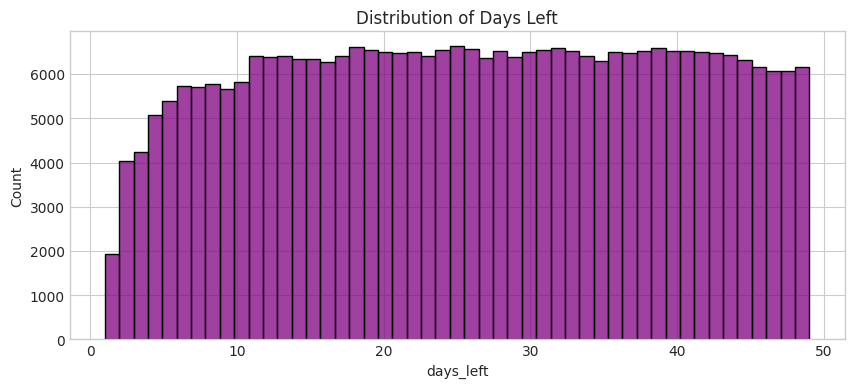

Bookings with days_left <=  3:  3.40%
Bookings with days_left <=  7: 10.70%
Bookings with days_left <= 15: 27.07%
Bookings with days_left <= 30: 59.47%


In [21]:
plt.figure(figsize=(10, 4)); sns.histplot(df['days_left'], bins=df['days_left'].nunique(), color='purple')
plt.title('Distribution of Days Left'); plt.show()
for k in [3, 7, 15, 30]:
    print(f'Bookings with days_left <= {k:2d}: {(df.days_left <= k).mean() * 100:5.2f}%')

**Insight:** Bookings are not concentrated close to departure. Only 3.4% are made within 3 days and 10.7% within 7 days, while 59.5% are made within 30 days.

## Section C - Airline-wise fare analysis

### Mean, median, min, max fare per airline; highest median?

In [22]:
airline_stats = (df.groupby('airline')['price']
                   .agg(count='count', mean='mean', median='median', min='min', max='max', std='std')
                   .sort_values('median', ascending=False))
display(airline_stats.round(0))
print('Highest median fare:', airline_stats['median'].idxmax())

,count,mean,median,min,max,std
airline,,,,,,
Vistara,127859,"30,397.00","15,543.00",1714,123071,"25,637.00"
Air_India,80892,"23,507.00","11,520.00",1526,90970,"20,905.00"
SpiceJet,9011,"6,179.00","5,654.00",1106,34158,"3,000.00"
GO_FIRST,23173,"5,652.00","5,336.00",1105,32803,"2,514.00"
Indigo,43120,"5,324.00","4,453.00",1105,31952,"3,269.00"
AirAsia,16098,"4,091.00","3,276.00",1105,31917,"2,824.00"


Highest median fare: Vistara


**Insight:** Vistara has the highest median fare (Rs 15,543), followed by Air India (Rs 11,520). The low-cost airlines are much cheaper: SpiceJet (Rs 5,654), GO FIRST (Rs 5,336), Indigo (Rs 4,453) and AirAsia, the cheapest, at Rs 3,276.

### Boxplots per airline; which has the largest variation?

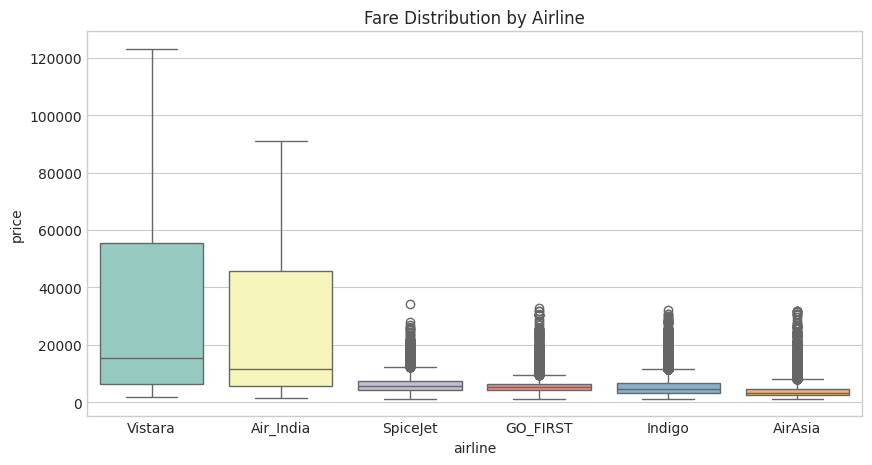

Largest std  : Vistara
Largest range: Vistara


In [23]:
order = airline_stats.sort_values('median', ascending=False).index
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='airline', y='price', order=order, palette='Set3')
plt.title('Fare Distribution by Airline'); plt.show()
print('Largest std  :', airline_stats['std'].idxmax())
print('Largest range:', (airline_stats['max'] - airline_stats['min']).idxmax())

**Insight:** Vistara shows the largest variation (std Rs 25,637 and the widest range) because it sells both Economy and Business tickets. Low-cost airlines have tight fare ranges.

### Rank airlines by median vs mean - does the ranking change?

In [24]:
rank = pd.DataFrame({'rank_by_median': airline_stats['median'].rank(ascending=False),
                     'rank_by_mean': airline_stats['mean'].rank(ascending=False)}).sort_values('rank_by_median')
rank['changed'] = rank['rank_by_median'] != rank['rank_by_mean']
display(rank)

,rank_by_median,rank_by_mean,changed
airline,,,
Vistara,1.00,1.00,False
Air_India,2.00,2.00,False
SpiceJet,3.00,3.00,False
GO_FIRST,4.00,4.00,False
Indigo,5.00,5.00,False
AirAsia,6.00,6.00,False


**Insight:** The ranking by median and by mean is identical (Vistara, Air India, SpiceJet, GO FIRST, Indigo, AirAsia), so the airline ranking is stable.

### Number of flights per airline - is the busiest also the cheapest?

In [25]:
cnt = df['airline'].value_counts().rename('flights')
cmp_df = airline_stats[['median', 'min']].join(cnt).sort_values('flights', ascending=False)
display(cmp_df)
print('Most records :', cnt.idxmax(), '| Cheapest by median:', airline_stats['median'].idxmin())

,median,min,flights
airline,,,
Vistara,"15,543.00",1714,127859
Air_India,"11,520.00",1526,80892
Indigo,"4,453.00",1105,43120
GO_FIRST,"5,336.00",1105,23173
AirAsia,"3,276.00",1105,16098
SpiceJet,"5,654.00",1106,9011


Most records : Vistara | Cheapest by median: AirAsia


**Insight:** The busiest airline (Vistara) is the most expensive, not the cheapest. The cheapest airline by median, AirAsia, has fewer records (16,098).

### Economy vs Business fare gap for every airline

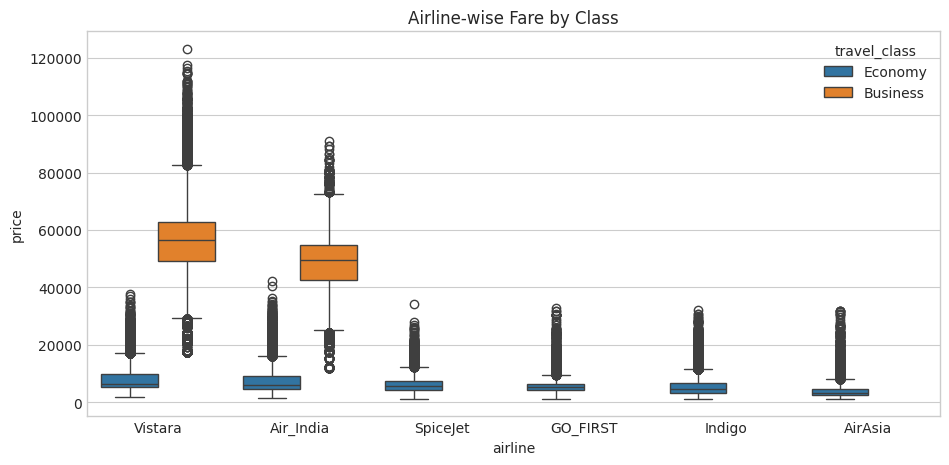

travel_class,Business,Economy,gap,multiple
airline,,,,
AirAsia,NaN,"3,276.00",NaN,NaN
Air_India,"49,613.00","6,082.00","43,531.00",8.20
GO_FIRST,NaN,"5,336.00",NaN,NaN
Indigo,NaN,"4,453.00",NaN,NaN
SpiceJet,NaN,"5,654.00",NaN,NaN
Vistara,"56,588.00","6,461.00","50,127.00",8.80


In [26]:
plt.figure(figsize=(11, 5))
sns.boxplot(data=df, x='airline', y='price', hue='travel_class', order=order)
plt.title('Airline-wise Fare by Class'); plt.show()

gap = df.pivot_table(index='airline', columns='travel_class', values='price', aggfunc='median')
if {'Business', 'Economy'}.issubset(gap.columns):
    gap['gap'] = gap['Business'] - gap['Economy']
    gap['multiple'] = gap['Business'] / gap['Economy']
display(gap.round(1))

**Insight:** Only Vistara and Air India offer Business class. The Business median is about 8.8 times Economy for Vistara (Rs 56,588 vs Rs 6,461) and about 8.2 times for Air India (Rs 49,613 vs Rs 6,082). The other four airlines are Economy-only, which is why they show NaN.

### Cheapest and most expensive airline per route (routes with enough observations)

In [27]:
df['route'] = df['source_city'] + ' - ' + df['destination_city']
MIN_OBS = 30

def extreme_airlines(data, min_obs=MIN_OBS):
    g = (data.groupby(['route', 'airline'])['price']
             .agg(count='count', median='median').reset_index())
    g = g[g['count'] >= min_obs]
    cheap = g.loc[g.groupby('route')['median'].idxmin(), ['route', 'airline', 'median']]
    cheap.columns = ['route', 'cheapest_airline', 'cheapest_median']
    exp = g.loc[g.groupby('route')['median'].idxmax(), ['route', 'airline', 'median']]
    exp.columns = ['route', 'costliest_airline', 'costliest_median']
    return g, cheap.merge(exp, on='route')

g_all, res_all = extreme_airlines(df)
print('Overall (Economy + Business mixed):'); display(res_all.head(15))
g_eco, res_eco = extreme_airlines(df[df.travel_class == 'Economy'])
print('Economy only (fairer comparison):'); display(res_eco.head(15))

Overall (Economy + Business mixed):


,route,cheapest_airline,cheapest_median,costliest_airline,costliest_median
0,Bangalore - Chennai,AirAsia,"1,715.00",Air_India,"13,316.50"
1,Bangalore - Delhi,AirAsia,"3,467.00",Vistara,"32,923.00"
2,Bangalore - Hyderabad,AirAsia,"1,714.00",Vistara,"14,150.00"
3,Bangalore - Kolkata,AirAsia,"3,393.00",Vistara,"51,817.00"
4,Bangalore - Mumbai,AirAsia,"2,203.00",Vistara,"20,760.00"
5,Chennai - Bangalore,AirAsia,"1,548.00",Vistara,"15,439.00"
6,Chennai - Delhi,AirAsia,"2,477.00",Vistara,"16,140.00"
7,Chennai - Hyderabad,GO_FIRST,"1,105.00",Vistara,"15,563.00"
8,Chennai - Kolkata,AirAsia,"2,361.00",Air_India,"15,963.00"
9,Chennai - Mumbai,AirAsia,"1,830.00",Vistara,"16,875.00"


Economy only (fairer comparison):


,route,cheapest_airline,cheapest_median,costliest_airline,costliest_median
0,Bangalore - Chennai,AirAsia,"1,715.00",Vistara,"6,510.00"
1,Bangalore - Delhi,AirAsia,"3,467.00",SpiceJet,"6,285.00"
2,Bangalore - Hyderabad,AirAsia,"1,714.00",Air_India,"6,620.00"
3,Bangalore - Kolkata,AirAsia,"3,393.00",Vistara,"8,112.00"
4,Bangalore - Mumbai,AirAsia,"2,203.00",Air_India,"6,578.00"
5,Chennai - Bangalore,AirAsia,"1,548.00",Vistara,"6,437.00"
6,Chennai - Delhi,AirAsia,"2,477.00",Vistara,"5,606.00"
7,Chennai - Hyderabad,GO_FIRST,"1,105.00",Vistara,"6,032.00"
8,Chennai - Kolkata,AirAsia,"2,361.00",Vistara,"7,764.00"
9,Chennai - Mumbai,AirAsia,"1,830.00",Air_India,"5,571.00"


**Insight:** AirAsia is the cheapest airline on most routes by median fare (GO FIRST on Chennai-Hyderabad), while Vistara or Air India is the most expensive. The Economy-only comparison is fairer because only two airlines sell Business class.

### % of each airline's records below the overall median fare

In [28]:
overall_median = df['price'].median()
below = (df['price'] < overall_median).groupby(df['airline']).mean().mul(100).sort_values(ascending=False)
display(below.round(2).to_frame('pct_below_overall_median'))

,pct_below_overall_median
airline,
AirAsia,91.17
GO_FIRST,87.70
Indigo,81.15
SpiceJet,75.79
Air_India,39.70
Vistara,31.74


**Insight:** AirAsia (91%), GO FIRST (88%) and Indigo (81%) have most of their fares below the overall median, while only about 32% of Vistara and 40% of Air India fares are below it.

### Does an airline's fare change with number of stops?

stops,one,two_or_more,zero
airline,,,
AirAsia,"3,090.00","3,175.00","3,862.00"
Air_India,"11,561.00","11,545.00","8,778.00"
GO_FIRST,"5,699.00","5,954.00","2,410.00"
Indigo,"4,748.00","6,858.00","3,551.00"
SpiceJet,"5,954.00",NaN,"4,499.00"
Vistara,"18,566.00","9,112.00","9,243.00"


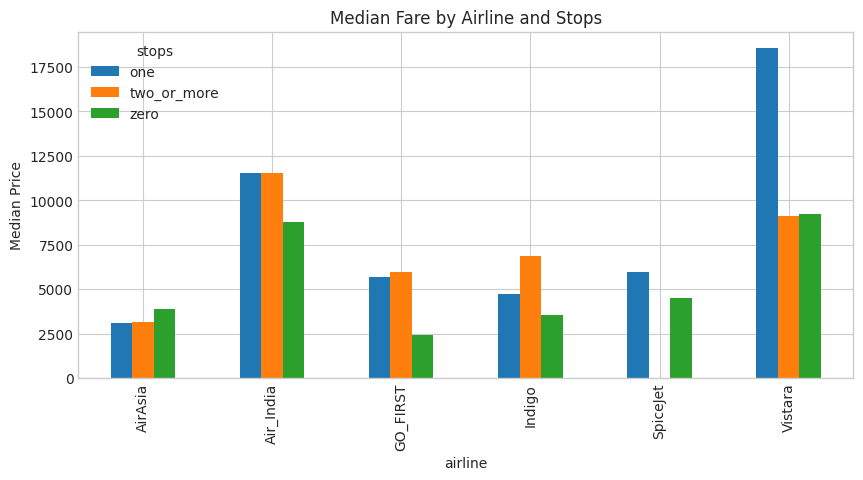

In [29]:
st = df.pivot_table(index='airline', columns='stops', values='price', aggfunc='median')
display(st.round(0))
st.plot(kind='bar', figsize=(10, 4.5)); plt.title('Median Fare by Airline and Stops'); plt.ylabel('Median Price'); plt.show()

**Insight:** Non-stop flights are usually cheaper: Air India Rs 8,778 vs Rs 11,561 (one-stop), GO FIRST Rs 2,410 vs Rs 5,699 and Indigo Rs 3,551 vs Rs 4,748. AirAsia is an exception. Vistara's one-stop looks costlier (Rs 18,566) probably because many Business tickets are on one-stop flights.

## Section D - Route, source and destination analysis

### Unique source-destination combinations and observations per route

In [30]:
route_counts = df['route'].value_counts()
print('Unique routes:', route_counts.shape[0])
display(route_counts.describe().to_frame('observations_per_route'))
display(route_counts.head(10).to_frame('observations'))

Unique routes: 30


,observations_per_route
count,30.00
mean,"10,005.10"
std,"2,646.65"
min,"6,103.00"
25%,"7,919.50"
50%,"9,926.00"
75%,"11,817.25"
max,"15,289.00"


,observations
route,
Delhi - Mumbai,15289
Mumbai - Delhi,14809
Delhi - Bangalore,14012
Bangalore - Delhi,13756
Bangalore - Mumbai,12939
Mumbai - Bangalore,12885
Mumbai - Kolkata,12602
Delhi - Kolkata,11934
Kolkata - Mumbai,11467


**Insight:** There are 30 routes with between 6,103 and 15,289 observations each. Delhi-Mumbai (15,289) and Mumbai-Delhi (14,809) have the most data.

### Route column (feature engineering)

In [31]:
# Feature Engineering: Concatenate Origin and Destination for Route Analysis
df['route'] = df['source_city'] + ' - ' + df['destination_city']
display(df[['source_city', 'destination_city', 'route']].head())

,source_city,destination_city,route
0,Delhi,Mumbai,Delhi - Mumbai
1,Delhi,Mumbai,Delhi - Mumbai
2,Delhi,Mumbai,Delhi - Mumbai
3,Delhi,Mumbai,Delhi - Mumbai
4,Delhi,Mumbai,Delhi - Mumbai


**Insight:** Joining the source and destination cities creates a route feature that is used for the route-level analysis.

### Average and median fare per route - highest and lowest routes

In [32]:
route_stats = df.groupby('route')['price'].agg(count='count', mean='mean', median='median').round(0)
print('Top 5 routes by median fare');    display(route_stats.sort_values('median', ascending=False).head(5))
print('Bottom 5 routes by median fare'); display(route_stats.sort_values('median').head(5))

Top 5 routes by median fare


,count,mean,median
route,,,
Chennai - Bangalore,6493,"25,082.00","10,469.00"
Bangalore - Chennai,6410,"23,322.00","9,241.00"
Kolkata - Chennai,6653,"23,660.00","8,589.00"
Kolkata - Hyderabad,7897,"21,500.00","8,467.00"
Chennai - Kolkata,6983,"22,670.00","8,394.00"


Bottom 5 routes by median fare


,count,mean,median
route,,,
Delhi - Hyderabad,9328,"17,347.00","6,109.00"
Hyderabad - Delhi,8506,"17,244.00","6,138.00"
Mumbai - Delhi,14809,"18,725.00","6,300.00"
Hyderabad - Mumbai,10064,"20,081.00","6,633.00"
Delhi - Bangalore,14012,"17,880.00","6,642.00"


**Insight:** The highest median fares are on Chennai-Bangalore (Rs 10,469), Bangalore-Chennai (Rs 9,241) and Kolkata-Chennai (Rs 8,589). The lowest are on Delhi-Hyderabad (Rs 6,109), Hyderabad-Delhi (Rs 6,138) and Mumbai-Delhi (Rs 6,300).

### Are fares from Delhi to Mumbai similar to Mumbai to Delhi?

In [33]:
rm = df.groupby('route')['price'].median()
rows = []
for r, v in rm.items():
    s, d_ = r.split(' - ')
    rev = f'{d_} - {s}'
    if rev in rm.index and s < d_:
        rows.append([f'{s} <-> {d_}', v, rm[rev], v - rm[rev]])
dir_df = pd.DataFrame(rows, columns=['pair', 'median_A_to_B', 'median_B_to_A', 'difference'])
display(dir_df.round(0))
if 'Delhi - Mumbai' in rm.index and 'Mumbai - Delhi' in rm.index:
    print(f"Delhi -> Mumbai: Rs {rm['Delhi - Mumbai']:,.0f}  |  Mumbai -> Delhi: Rs {rm['Mumbai - Delhi']:,.0f}")

,pair,median_A_to_B,median_B_to_A,difference
0,Bangalore <-> Chennai,"9,241.00","10,469.00","-1,228.00"
1,Bangalore <-> Delhi,"7,164.00","6,642.00",522.00
2,Bangalore <-> Hyderabad,"7,813.00","7,091.00",722.00
3,Bangalore <-> Kolkata,"8,112.00","8,111.00",1.00
4,Bangalore <-> Mumbai,"7,113.00","7,192.00",-79.00
5,Chennai <-> Delhi,"7,352.00","7,425.00",-73.00
6,Chennai <-> Hyderabad,"7,373.00","7,702.00",-329.00
7,Chennai <-> Kolkata,"8,394.00","8,589.00",-195.00
8,Chennai <-> Mumbai,"8,233.00","8,148.00",85.00
9,Delhi <-> Hyderabad,"6,109.00","6,138.00",-29.00


Delhi -> Mumbai: Rs 7,262  |  Mumbai -> Delhi: Rs 6,300


**Insight:** Fares are broadly similar in both directions for most city pairs. Delhi to Mumbai (Rs 7,262) is about Rs 962 higher than Mumbai to Delhi (Rs 6,300), and the largest gap is on Bangalore and Chennai (about Rs 1,228).

### Pivot table: source (rows) x destination (columns), median price

In [34]:
pivot = df.pivot_table(index='source_city', columns='destination_city', values='price', aggfunc='median')
display(pivot.round(0))

destination_city,Bangalore,Chennai,Delhi,Hyderabad,Kolkata,Mumbai
source_city,,,,,,
Bangalore,NaN,"9,241.00","7,164.00","7,813.00","8,112.00","7,113.00"
Chennai,"10,469.00",NaN,"7,352.00","7,373.00","8,394.00","8,233.00"
Delhi,"6,642.00","7,425.00",NaN,"6,109.00","7,084.00","7,262.00"
Hyderabad,"7,091.00","7,702.00","6,138.00",NaN,"7,767.00","6,633.00"
Kolkata,"8,111.00","8,589.00","6,723.00","8,467.00",NaN,"7,958.00"
Mumbai,"7,192.00","8,148.00","6,300.00","7,584.00","7,518.00",NaN


**Insight:** Median fares across city pairs range from about Rs 6,100 to Rs 10,500. Routes involving Delhi are generally among the cheapest, while Chennai-Bangalore is the most expensive.

### Heatmap of median fares

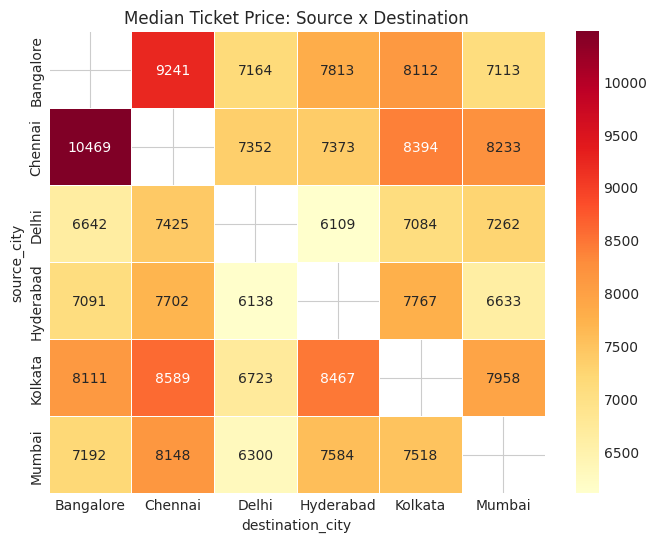

In [35]:
plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=.5)
plt.title('Median Ticket Price: Source x Destination'); plt.show()

**Insight:** The heatmap shows the same pattern visually: darker (costlier) cells for pairs involving Chennai, Bangalore and Kolkata and lighter cells for Delhi-related pairs.

### Number of flights vs median fare per route - more observations = lower prices?

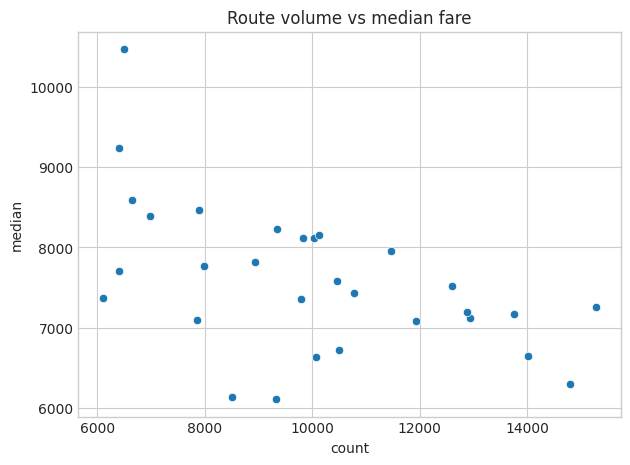

Spearman correlation: -0.5


In [36]:
rs = route_stats[['count', 'median']]
plt.figure(figsize=(7, 5)); sns.scatterplot(data=rs, x='count', y='median'); plt.title('Route volume vs median fare'); plt.show()
print('Spearman correlation:', round(rs.corr(method='spearman').loc['count', 'median'], 3))

**Insight:** The Spearman correlation is -0.5, so routes with more flights tend to have lower median fares (more competition and more low-cost options). The relationship is moderate, not perfect.

### Cheapest airline per route vs the route-wide median

In [37]:
route_med = df.groupby('route')['price'].median().rename('route_median')
cheap_vs = res_eco.set_index('route')[['cheapest_airline', 'cheapest_median']].join(route_med)
cheap_vs['pct_vs_route_median'] = (cheap_vs['cheapest_median'] / cheap_vs['route_median'] - 1) * 100
display(cheap_vs.round(1).head(15))

,cheapest_airline,cheapest_median,route_median,pct_vs_route_median
route,,,,
Bangalore - Chennai,AirAsia,"1,715.00","9,241.00",-81.40
Bangalore - Delhi,AirAsia,"3,467.00","7,164.00",-51.60
Bangalore - Hyderabad,AirAsia,"1,714.00","7,813.00",-78.10
Bangalore - Kolkata,AirAsia,"3,393.00","8,112.00",-58.20
Bangalore - Mumbai,AirAsia,"2,203.00","7,113.00",-69.00
Chennai - Bangalore,AirAsia,"1,548.00","10,469.00",-85.20
Chennai - Delhi,AirAsia,"2,477.00","7,352.00",-66.30
Chennai - Hyderabad,GO_FIRST,"1,105.00","7,373.00",-85.00
Chennai - Kolkata,AirAsia,"2,361.00","8,394.00",-71.90


**Insight:** On every route the cheapest airline's median is far below the route median. For example AirAsia charges Rs 1,715 on Bangalore-Chennai against a route median of Rs 9,241 (about 80% lower).

### (Section D). Effect of stops on price across routes

stops,one,two_or_more,zero
route,,,
Bangalore - Delhi,"7,484.00","2,723.00","4,756.00"
Bangalore - Mumbai,"7,317.00","5,675.00","2,309.00"
Delhi - Bangalore,"6,963.00","6,008.00","4,721.00"
Delhi - Mumbai,"9,768.00","6,323.00","3,100.00"
Mumbai - Bangalore,"8,122.00","9,279.00","2,124.00"
Mumbai - Delhi,"8,777.00","5,942.00","3,024.00"


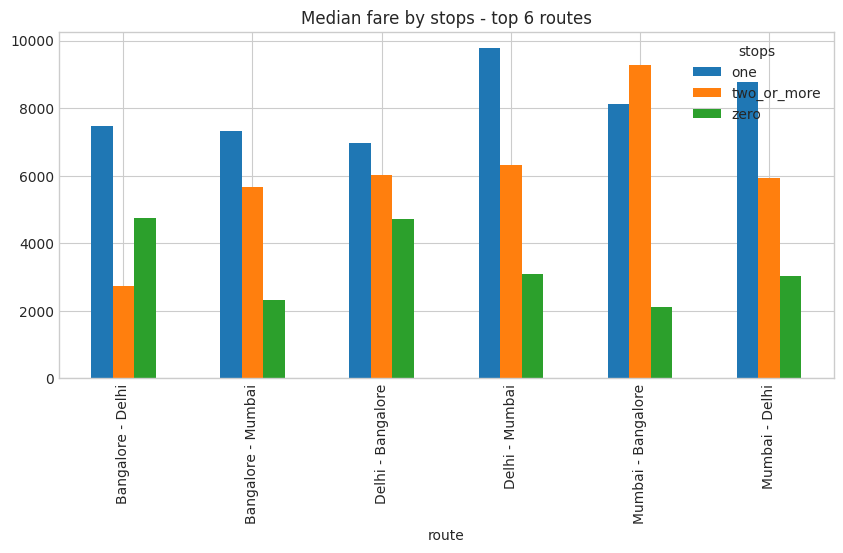

In [38]:
top_routes = df['route'].value_counts().head(6).index
rt = (df[df.route.isin(top_routes)].pivot_table(index='route', columns='stops', values='price', aggfunc='median'))
display(rt.round(0))
rt.plot(kind='bar', figsize=(10, 4.5)); plt.title('Median fare by stops - top 6 routes'); plt.show()

**Insight:** Non-stop flights are much cheaper than one-stop flights on all six busiest routes (for example Delhi-Mumbai Rs 3,100 vs Rs 9,768) and are the cheapest overall on five of the six. The effect of two or more stops is not consistent across routes.

## Section E - Booking window and Days Left analysis

### (Section E). Scatter plot: Days Left vs Price

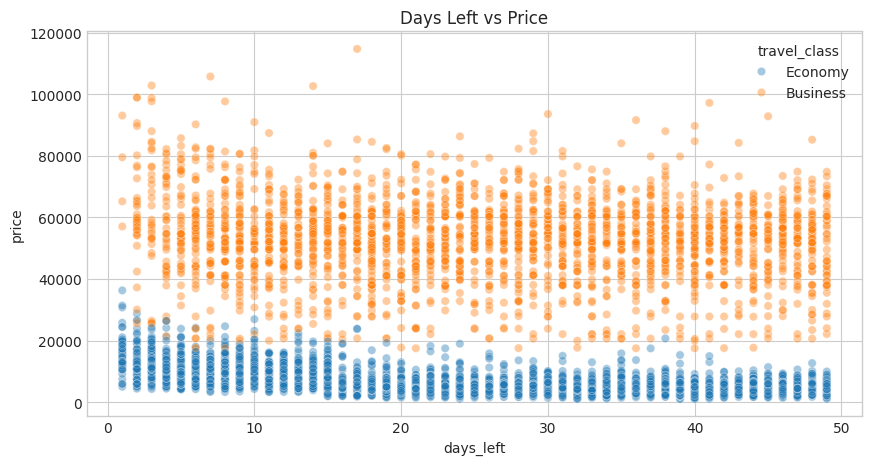

Spearman (days_left, price): -0.267


In [39]:
samp = df.sample(min(8000, len(df)), random_state=42)
plt.figure(figsize=(10, 5))
sns.scatterplot(data=samp, x='days_left', y='price', hue='travel_class', alpha=.4)
plt.title('Days Left vs Price'); plt.show()
print('Spearman (days_left, price):', round(df[['days_left', 'price']].corr(method='spearman').iloc[0, 1], 3))

**Insight:** The relationship is nonlinear and widely scattered. Prices rise sharply in the last days before departure, and two bands (Economy and Business) are visible. Spearman correlation is -0.27, meaning more days left generally means a lower price.

### Mean and median price for every value of Days Left

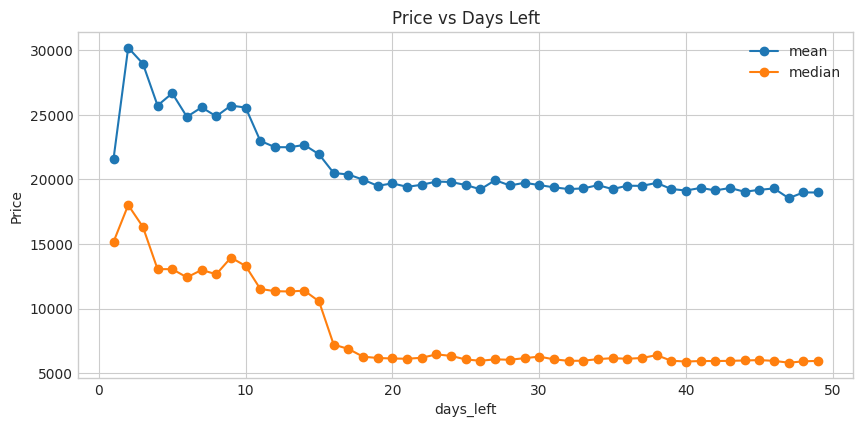

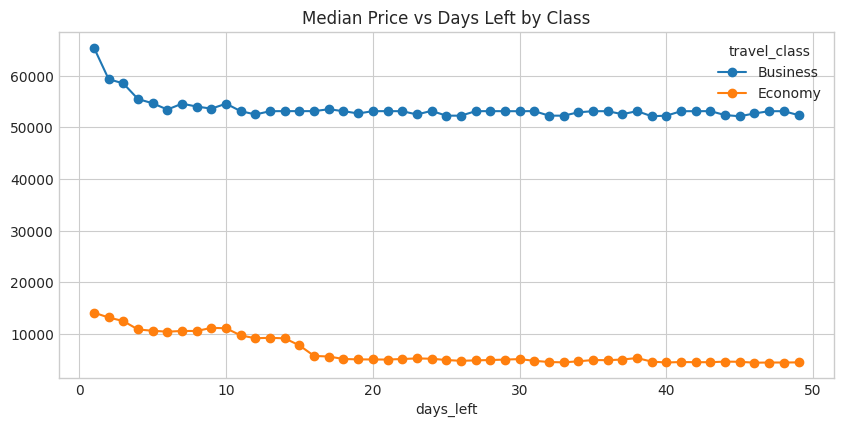

In [40]:
dl = df.groupby('days_left')['price'].agg(['mean', 'median'])
dl.plot(figsize=(10, 4.5), marker='o'); plt.title('Price vs Days Left'); plt.ylabel('Price'); plt.show()

dl_c = df.pivot_table(index='days_left', columns='travel_class', values='price', aggfunc='median')
dl_c.plot(figsize=(10, 4.5), marker='o'); plt.title('Median Price vs Days Left by Class'); plt.show()

**Insight:** Both mean and median price fall as days left increases. Prices are highest in the last few days and become almost flat after roughly 15 to 16 days.

### Booking-window groups; average and median fare per group

,count,mean,median
booking_window,,,
0-3,10201,"28,069.00","16,572.00"
4-7,21912,"25,698.00","12,978.00"
8-15,49145,"23,534.00","11,893.00"
16-30,97234,"19,754.00","6,228.00"
31-45,97200,"19,336.00","6,056.00"
46-60,24461,"18,964.00","5,896.00"


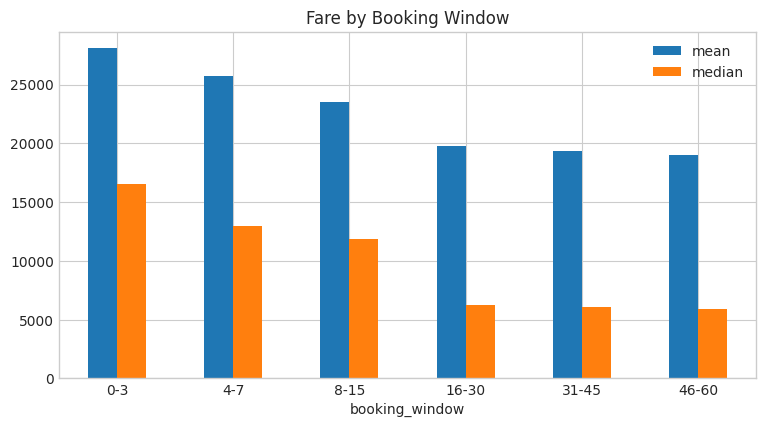

In [41]:
bins = [-1, 3, 7, 15, 30, 45, 60, np.inf]
labels = ['0-3', '4-7', '8-15', '16-30', '31-45', '46-60', '60+']
df['booking_window'] = pd.cut(df['days_left'], bins=bins, labels=labels, ordered=True).cat.remove_unused_categories()
bw = df.groupby('booking_window', observed=True)['price'].agg(count='count', mean='mean', median='median')
display(bw.round(0))
bw[['mean', 'median']].plot(kind='bar', figsize=(9, 4.5)); plt.title('Fare by Booking Window'); plt.xticks(rotation=0); plt.show()

**Insight:** Median fare by booking window: 0-3 days Rs 16,572, 4-7 days Rs 12,978, 8-15 days Rs 11,893, 16-30 days Rs 6,228, 31-45 days Rs 6,056 and 46-60 days Rs 5,896. The largest drop is between the 8-15 and 16-30 day groups. The dataset has no 60+ day group because days_left only goes up to 49.

### Highest and lowest median-fare booking window

In [42]:
print('Highest median:', bw['median'].idxmax(), f"(Rs {bw['median'].max():,.0f})")
print('Lowest median :', bw['median'].idxmin(), f"(Rs {bw['median'].min():,.0f})")

Highest median: 0-3 (Rs 16,572)
Lowest median : 46-60 (Rs 5,896)


**Insight:** The highest median fare is in the 0-3 day window (Rs 16,572) and the lowest is in the 46-60 day window (Rs 5,896).

### Days Left vs Price - Economy vs Business

travel_class,Business,Economy
booking_window,,
0-3,"59,306.00","13,182.00"
4-7,"54,608.00","10,680.00"
8-15,"53,209.00","9,840.00"
16-30,"53,152.00","5,152.00"
31-45,"52,715.00","4,755.00"
46-60,"53,152.00","4,499.00"


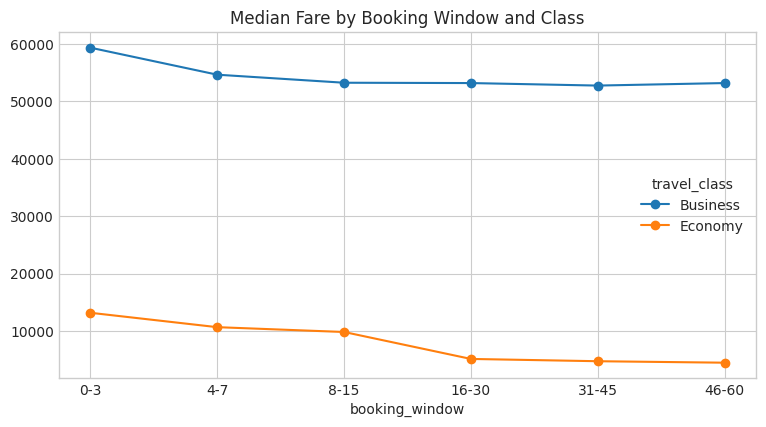

In [43]:
bwc = df.pivot_table(index='booking_window', columns='travel_class', values='price', aggfunc='median', observed=True)
display(bwc.round(0))
bwc.plot(marker='o', figsize=(9, 4.5)); plt.title('Median Fare by Booking Window and Class'); plt.show()

**Insight:** Economy fares rise steeply close to departure (Rs 4,499 to Rs 13,182, +193%), while Business fares are almost flat (Rs 53,152 to Rs 59,306, +11.6%). Economy shows a big step around 15 days (Rs 9,840 for 8-15 days vs Rs 5,152 for 16-30 days).

### Booking-window effect by airline (major airlines)

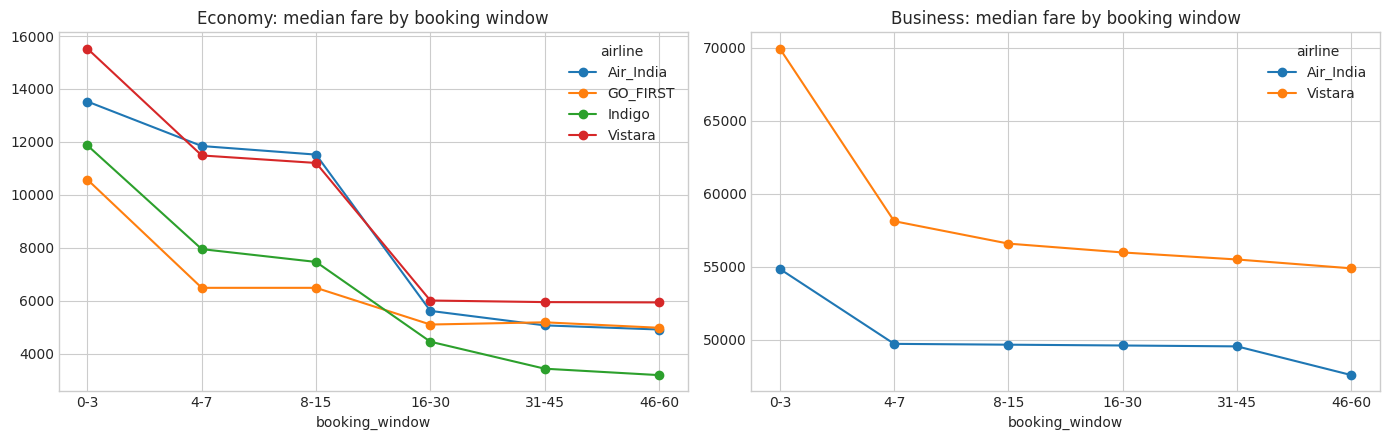

In [44]:
major = df['airline'].value_counts().head(4).index
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)
for a, cls in zip(ax, ['Economy', 'Business']):
    sub = df[(df.airline.isin(major)) & (df.travel_class == cls)]
    t = sub.pivot_table(index='booking_window', columns='airline', values='price', aggfunc='median', observed=True)
    t.plot(marker='o', ax=a); a.set_title(f'{cls}: median fare by booking window')
plt.tight_layout(); plt.show()

**Insight:** The major airlines appear to follow the same downward trend: fares are highest for last-minute bookings and fall for early bookings, with Vistara and Air India at a higher level than the low-cost carriers.

### Booking-window pattern: non-stop vs connecting flights

stops,one,two_or_more,zero
booking_window,,,
0-3,"17,606.00","17,484.00","8,055.00"
4-7,"13,372.00","14,028.00","6,973.00"
8-15,"12,387.00","13,225.00","6,489.00"
16-30,"6,437.00","7,770.00","3,450.00"
31-45,"6,186.00","7,106.00","3,191.00"
46-60,"6,074.00","6,968.00","3,108.00"


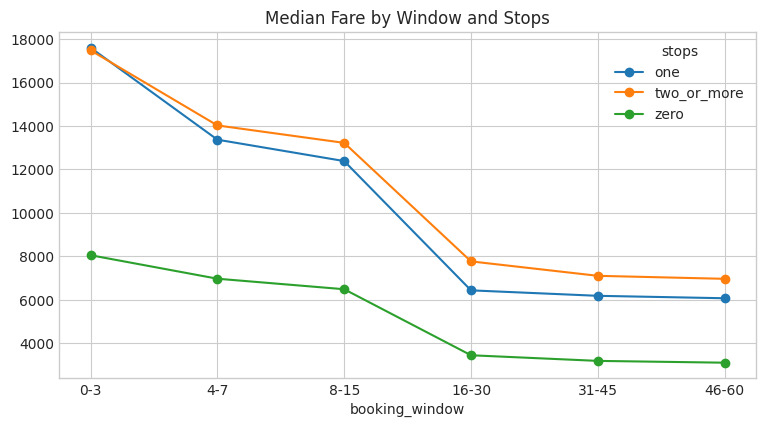

In [45]:
bs = df.pivot_table(index='booking_window', columns='stops', values='price', aggfunc='median', observed=True)
display(bs.round(0))
bs.plot(marker='o', figsize=(9, 4.5)); plt.title('Median Fare by Window and Stops'); plt.show()

**Insight:** Non-stop flights are cheapest in every booking window (for example Rs 3,108 vs Rs 6,074 for one-stop at 46-60 days). All stop types become expensive in the last 15 days.

### Booking-window trends on high-volume routes (Economy) - consistent?

route,Bangalore - Delhi,Delhi - Bangalore,Delhi - Mumbai,Mumbai - Delhi
booking_window,,,,
0-3,"12,969.00","12,413.00","12,912.00","12,243.00"
4-7,"10,534.00","10,461.00","9,840.00","9,876.00"
8-15,"10,009.00","9,735.00","8,396.00","6,921.00"
16-30,"4,111.00","4,496.00","4,590.00","4,478.00"
31-45,"4,111.00","4,427.00","4,170.00","4,158.00"
46-60,"4,111.00","4,230.00","4,107.00","3,819.00"


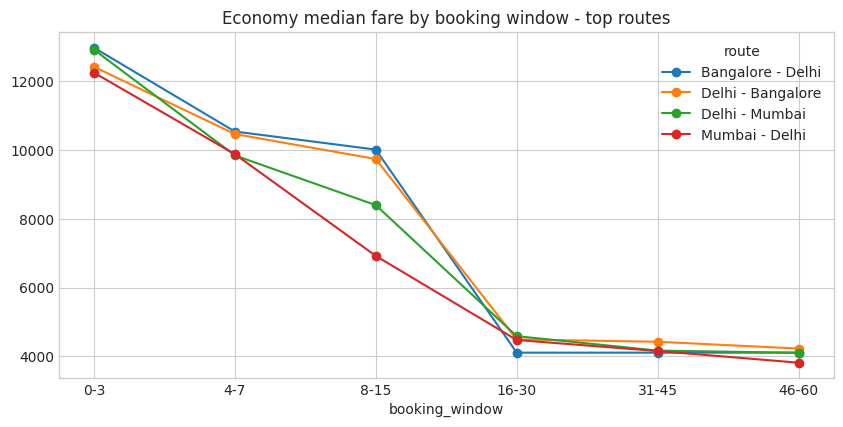

                   spearman_window_vs_fare
route                                     
Bangalore - Delhi                    -0.94
Delhi - Bangalore                    -1.00
Delhi - Mumbai                       -1.00
Mumbai - Delhi                       -1.00


In [46]:
top4 = df['route'].value_counts().head(4).index
rtw = (df[(df.route.isin(top4)) & (df.travel_class == 'Economy')]
         .pivot_table(index='booking_window', columns='route', values='price', aggfunc='median', observed=True))
display(rtw.round(0))
rtw.plot(marker='o', figsize=(10, 4.5)); plt.title('Economy median fare by booking window - top routes'); plt.show()
# Consistency check: rank correlation between window order and fare for each route
order_idx = pd.Series(range(len(rtw)), index=rtw.index)
print(rtw.apply(lambda col: col.corr(order_idx, method='spearman')).round(2).to_frame('spearman_window_vs_fare'))

**Insight:** The Economy trend is consistent on the busiest routes: the Spearman correlation between booking window and fare is between -0.94 and -1.0, so fares fall steadily as people book earlier. For example Delhi-Mumbai is Rs 12,912 at 0-3 days versus Rs 4,107 at 46-60 days.

### % change in median price: earliest vs latest booking window

In [47]:
def pct_change_windows(data):
    m = data.groupby('booking_window', observed=True)['price'].median()
    latest, earliest = m.index[0], m.index[-1]          # 0-3 days vs the longest window present
    ch = (m[latest] - m[earliest]) / m[earliest] * 100
    return latest, earliest, m[latest], m[earliest], ch

for name, data in [('All', df), ('Economy', df[df.travel_class == 'Economy']), ('Business', df[df.travel_class == 'Business'])]:
    la, ea, ml, me, ch = pct_change_windows(data)
    print(f'{name:9s}: {ea} (median Rs {me:,.0f}) -> {la} (median Rs {ml:,.0f}) = {ch:+.1f}%')

All      : 46-60 (median Rs 5,896) -> 0-3 (median Rs 16,572) = +181.1%
Economy  : 46-60 (median Rs 4,499) -> 0-3 (median Rs 13,182) = +193.0%
Business : 46-60 (median Rs 53,152) -> 0-3 (median Rs 59,306) = +11.6%


**Insight:** Comparing 46-60 days with 0-3 days, the median fare rises by 181% overall, 193% for Economy and only 11.6% for Business.

## Section F - Flight duration, stops and time-of-day analysis

### Duration vs price - scatter, Pearson and Spearman

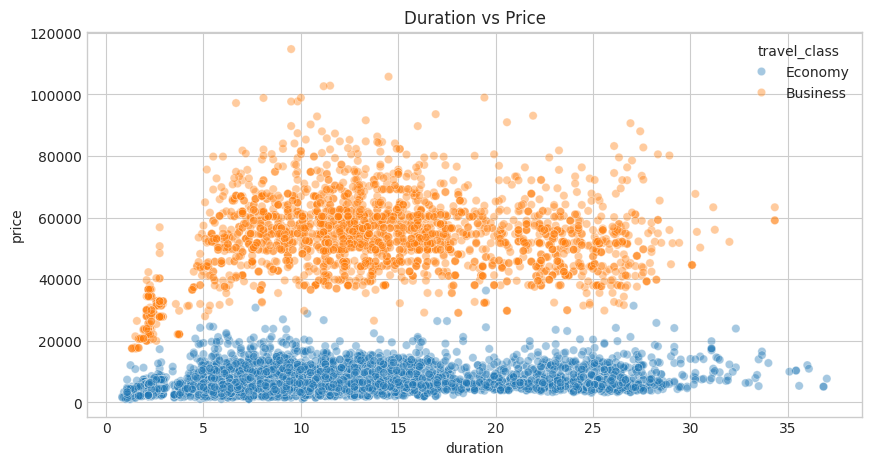

Pearson : 0.204
Spearman: 0.319


In [48]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=samp, x='duration', y='price', hue='travel_class', alpha=.4)
plt.title('Duration vs Price'); plt.show()
print('Pearson :', round(df['duration'].corr(df['price']), 3))
print('Spearman:', round(df['duration'].corr(df['price'], method='spearman'), 3))

**Insight:** Duration has a weak to moderate positive relationship with price (Pearson 0.20, Spearman 0.32). Longer flights tend to cost somewhat more but duration is not the main driver.

### Median prices for non-stop, one-stop, two-stop and other categories

,median_price
stops,
zero,"4,499.00"
one,"7,959.00"
two_or_more,"8,307.00"


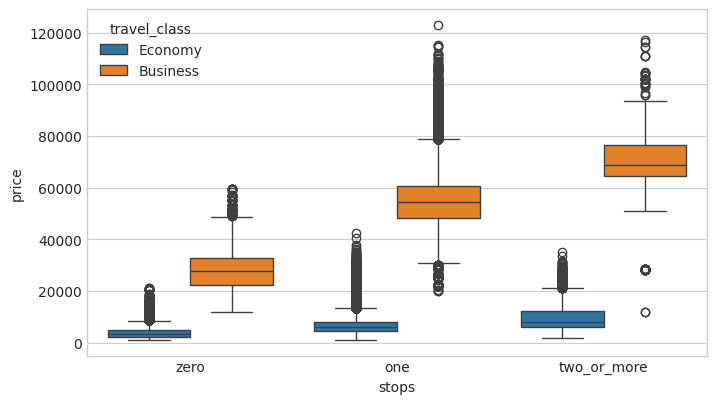

In [49]:
pref = ['zero', 'one', 'two_or_more']
stop_order = [s for s in pref if s in df['stops'].unique()] + [s for s in df['stops'].unique() if s not in pref]
display(df.groupby('stops')['price'].median().reindex(stop_order).to_frame('median_price'))
plt.figure(figsize=(8, 4.5)); sns.boxplot(data=df, x='stops', y='price', order=stop_order, hue='travel_class'); plt.show()

**Insight:** Median fare is Rs 4,499 for non-stop, Rs 7,959 for one-stop and Rs 8,307 for two or more stops. More stops means a higher fare, although one-stop and two-stop fares are close.

### Are longer flights more expensive within the same route? (control for route and class)

Within route+class Pearson : 0.204
Within route+class Spearman: 0.237


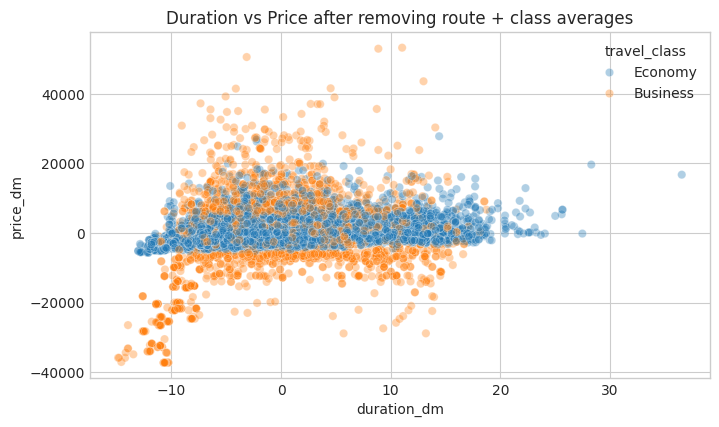

In [50]:
grp = df.groupby(['route', 'travel_class'])
df['duration_dm'] = df['duration'] - grp['duration'].transform('mean')
df['price_dm'] = df['price'] - grp['price'].transform('mean')
print('Within route+class Pearson :', round(df['duration_dm'].corr(df['price_dm']), 3))
print('Within route+class Spearman:', round(df['duration_dm'].corr(df['price_dm'], method='spearman'), 3))
s2 = df.sample(min(8000, len(df)), random_state=1)
plt.figure(figsize=(8, 4.5)); sns.scatterplot(data=s2, x='duration_dm', y='price_dm', hue='travel_class', alpha=.35)
plt.title('Duration vs Price after removing route + class averages'); plt.show()

**Insight:** Even after removing route and class averages the correlation between duration and price stays weak (Pearson 0.20, Spearman 0.24), so on the same route longer flights are only slightly more expensive.

### Fare by departure period - which has the highest median fare?

,median_price
departure_time,
Early_Morning,"7,212.00"
Morning,"8,112.00"
Afternoon,"6,663.00"
Evening,"7,425.00"
Night,"7,813.00"
Late_Night,"4,499.00"


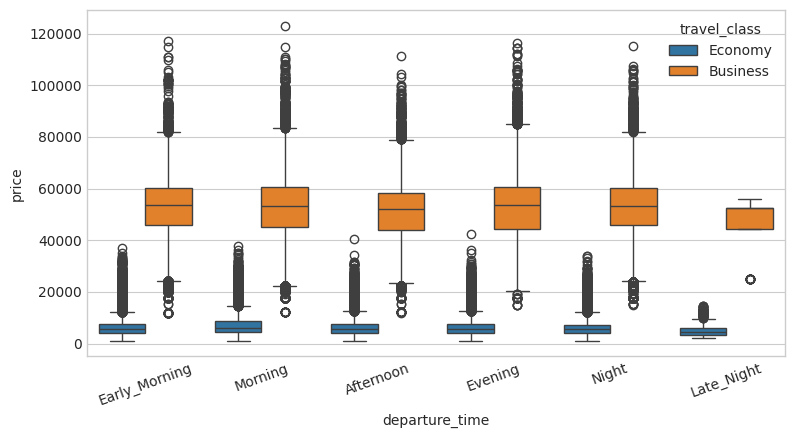

Highest median departure period: Morning


In [51]:
time_order = [t for t in ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night'] if t in df['departure_time'].unique()]
dep = df.groupby('departure_time')['price'].median().reindex(time_order)
display(dep.to_frame('median_price'))
plt.figure(figsize=(9, 4.5)); sns.boxplot(data=df, x='departure_time', y='price', order=time_order, hue='travel_class'); plt.xticks(rotation=20); plt.show()
print('Highest median departure period:', dep.idxmax())

**Insight:** Morning departures have the highest median fare (Rs 8,112), followed by Night (Rs 7,813) and Evening (Rs 7,425). Late Night departures are the cheapest (Rs 4,499).

### Repeat for arrival period

,median_price
arrival_time,
Early_Morning,"5,800.00"
Morning,"7,687.00"
Afternoon,"6,714.00"
Evening,"8,854.00"
Night,"7,584.00"
Late_Night,"4,867.00"


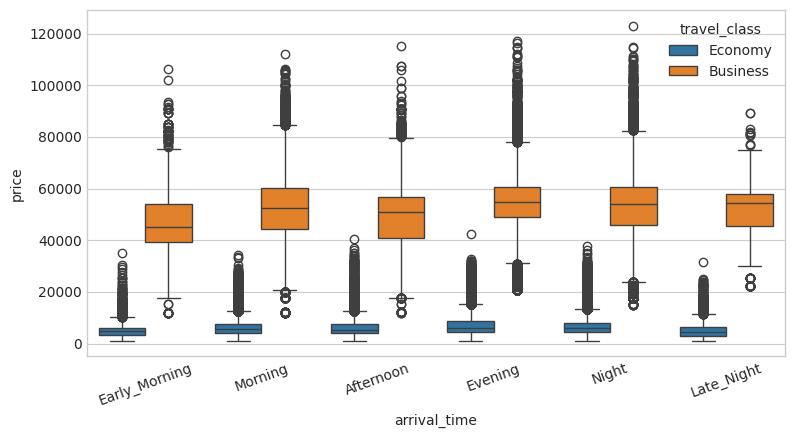

Highest median arrival period: Evening


In [52]:
arr = df.groupby('arrival_time')['price'].median().reindex(time_order)
display(arr.to_frame('median_price'))
plt.figure(figsize=(9, 4.5)); sns.boxplot(data=df, x='arrival_time', y='price', order=time_order, hue='travel_class'); plt.xticks(rotation=20); plt.show()
print('Highest median arrival period:', arr.idxmax())

**Insight:** Evening arrivals have the highest median fare (Rs 8,854) and Late Night arrivals the lowest (Rs 4,867). The pattern is similar to departure: business-hour travel costs more and late-night travel is cheapest.

### Does longer duration necessarily mean more stops?

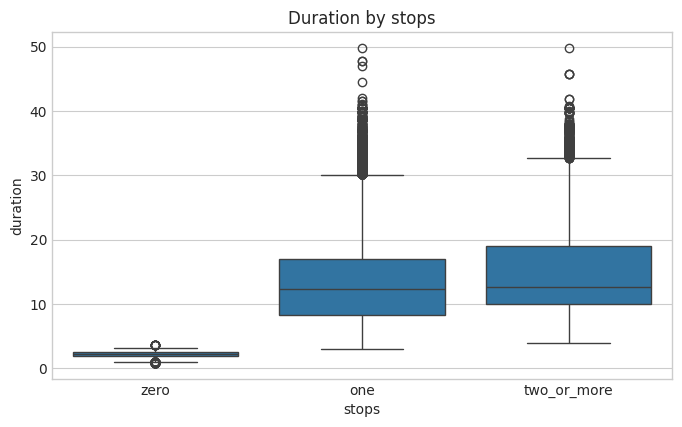

,count,mean,std,min,25%,50%,75%,max
stops,,,,,,,,
zero,"36,004.00",2.19,0.50,0.83,1.92,2.25,2.58,3.58
one,"250,863.00",13.50,6.51,2.92,8.25,12.25,17.00,49.83
two_or_more,"13,286.00",15.32,7.39,3.92,10.00,12.67,19.08,49.83


In [53]:
plt.figure(figsize=(8, 4.5)); sns.boxplot(data=df, x='stops', y='duration', order=stop_order); plt.title('Duration by stops'); plt.show()
display(df.groupby('stops')['duration'].describe().reindex(stop_order).round(2))

**Insight:** A longer duration does not necessarily mean more stops. Non-stop flights are short (mean 2.2 hours), but one-stop (13.5 hours) and two-or-more-stop flights (15.3 hours) overlap a lot, and some one-stop flights last almost 50 hours.

### Airline with shortest median duration per route - also the most expensive?

In [54]:
rd = (df.groupby(['route', 'airline'])
        .agg(median_duration=('duration', 'median'), median_price=('price', 'median'), n=('price', 'size')).reset_index())
rd = rd[rd.n >= MIN_OBS]
fast = rd.loc[rd.groupby('route')['median_duration'].idxmin(), ['route', 'airline', 'median_duration', 'median_price']]
costly = rd.loc[rd.groupby('route')['median_price'].idxmax(), ['route', 'airline']].rename(columns={'airline': 'most_expensive_airline'})
fc = fast.merge(costly, on='route')
fc['fastest_is_most_expensive'] = fc['airline'] == fc['most_expensive_airline']
display(fc.head(15).round(2))
print(f"Share of routes where the fastest airline is also the most expensive: {fc['fastest_is_most_expensive'].mean() * 100:.1f}%")

,route,airline,median_duration,median_price,most_expensive_airline,fastest_is_most_expensive
0,Bangalore - Chennai,AirAsia,1.00,"1,715.00",Air_India,False
1,Bangalore - Delhi,Indigo,5.92,"4,500.00",Vistara,False
2,Bangalore - Hyderabad,SpiceJet,1.08,"4,338.00",Vistara,False
3,Bangalore - Kolkata,SpiceJet,5.75,"4,814.00",Vistara,False
4,Bangalore - Mumbai,Indigo,5.17,"4,435.00",Vistara,False
5,Chennai - Bangalore,Indigo,1.08,"1,654.00",Vistara,False
6,Chennai - Delhi,Indigo,6.33,"4,071.00",Vistara,False
7,Chennai - Hyderabad,GO_FIRST,1.25,"1,105.00",Vistara,False
8,Chennai - Kolkata,SpiceJet,2.50,"4,620.00",Air_India,False
9,Chennai - Mumbai,GO_FIRST,1.92,"3,000.00",Vistara,False


Share of routes where the fastest airline is also the most expensive: 0.0%


**Insight:** On the routes with enough data the fastest airline is never the most expensive one (0.0% of routes). Fast flights are usually operated by low-cost carriers such as Indigo, SpiceJet and GO FIRST.

### Duration vs fare - Economy and Business separately

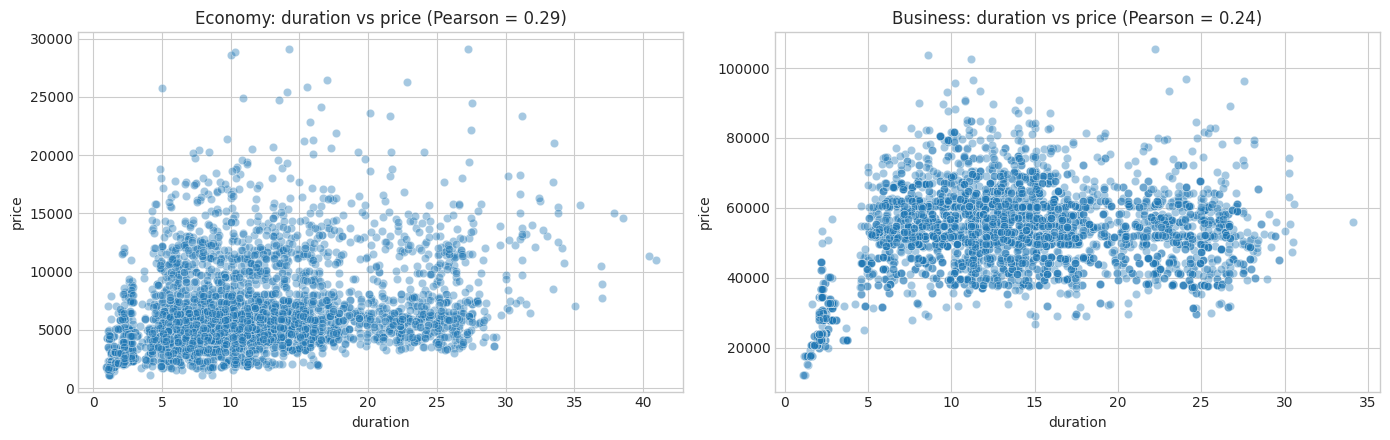

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, cls in zip(ax, ['Economy', 'Business']):
    sub = df[df.travel_class == cls]
    sns.scatterplot(data=sub.sample(min(4000, len(sub)), random_state=3), x='duration', y='price', alpha=.4, ax=a)
    a.set_title(f'{cls}: duration vs price (Pearson = {sub.duration.corr(sub.price):.2f})')
plt.tight_layout(); plt.show()

**Insight:** When Economy and Business are plotted separately, the relationship between duration and fare stays weak within each class. The overall correlation is partly caused by the difference between the two classes.

## 3. Consolidated Key Insights and Recommendations

In [56]:
eco = df[df.travel_class == 'Economy']
m = eco.groupby('booking_window', observed=True)['price'].median()
near = m['0-3']
far = m['16-30'] if '16-30' in m.index else m.iloc[-1]
mult = df[df.travel_class == 'Business']['price'].median() / eco['price'].median()
dmed = eco.groupby('departure_time')['price'].median()

insights = pd.DataFrame([
    ['Booking Window', f'Economy median fare in the 0-3 day window is {(near / far - 1) * 100:.0f}% higher than in the 16-30 day window.',
     'Promote advance-booking alerts in the 16-30 day window.'],
    ['Class Disparity', f'Business median fare is about {mult:.1f}x the Economy median fare.',
     'Target corporate accounts with customised Business bundles.'],
    ['Departure Timing', f'Highest median Economy fare: {dmed.idxmax()}; lowest: {dmed.idxmin()}.',
     'Highlight off-peak departure options to budget travellers.'],
], columns=['Analysis Vector', 'Observed Pattern', 'Strategic Action'])
display(insights.style.set_properties(**{'text-align': 'left'}))

,Analysis Vector,Observed Pattern,Strategic Action
0,Booking Window,Economy median fare in the 0-3 day window is 156% higher than in the 16-30 day window.,Promote advance-booking alerts in the 16-30 day window.
1,Class Disparity,Business median fare is about 9.2x the Economy median fare.,Target corporate accounts with customised Business bundles.
2,Departure Timing,Highest median Economy fare: Morning; lowest: Late_Night.,Highlight off-peak departure options to budget travellers.


**Insight:** Booking window, travel class and departure time are the three main pricing levers. Customers who book at least 16 days ahead pay far less in Economy, Business fares are about 9 times Economy, and Late Night departures are the cheapest. (Edit the Strategic Action column in your own words.)

## Section G - Fare prediction (baseline regression models)
**Objective:** Use the drivers found in the EDA (class, airline, stops, duration, days left, cities, times) to predict ticket price
and compare simple regression models. The flight code is excluded (high cardinality) and engineered columns such as
`route`, `booking_window`, `duration_dm` and `price_dm` are excluded to avoid data leakage.

In [57]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

cat_features = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time']
model_df = df[cat_features + ['stops', 'travel_class', 'duration', 'days_left', 'price']].copy()
model_df['stops'] = model_df['stops'].map({'zero': 0, 'one': 1, 'two_or_more': 2})
model_df['travel_class'] = (model_df['travel_class'] == 'Business').astype(int)

X = pd.get_dummies(model_df.drop(columns='price'), columns=cat_features, drop_first=True)
y = model_df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Features:', X.shape[1], '| Train rows:', len(X_train), '| Test rows:', len(X_test))

Features: 29 | Train rows: 240122 | Test rows: 60031


In [58]:
# NOTE: Random Forest can take a few minutes on the full dataset.
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=60, min_samples_leaf=2, n_jobs=-1, random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingRegressor(max_iter=200, random_state=42),
}
rows, preds = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p_ = m.predict(X_test)
    preds[name] = p_
    rows.append([name, mean_absolute_error(y_test, p_), np.sqrt(mean_squared_error(y_test, p_)), r2_score(y_test, p_)])
results = pd.DataFrame(rows, columns=['Model', 'MAE (Rs)', 'RMSE (Rs)', 'R2']).sort_values('R2', ascending=False)
display(results.round(3))

,Model,MAE (Rs),RMSE (Rs),R2
1,Random Forest,"1,103.78","2,715.75",0.99
2,Hist Gradient Boosting,"2,156.35","3,673.18",0.97
0,Linear Regression,"4,500.71","6,814.94",0.91


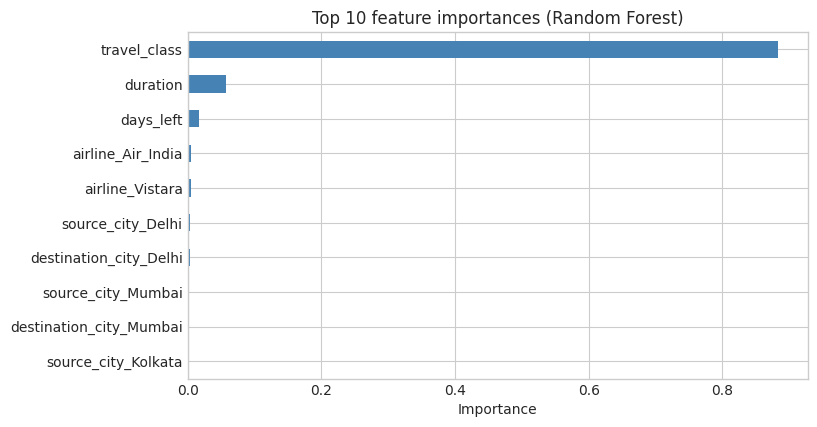

,importance
travel_class,0.88
duration,0.06
days_left,0.02
airline_Air_India,0.01
airline_Vistara,0.00
source_city_Delhi,0.00
destination_city_Delhi,0.00
source_city_Mumbai,0.00
destination_city_Mumbai,0.00
source_city_Kolkata,0.00


In [59]:
rf = models['Random Forest']
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 4.5))
imp.sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 10 feature importances (Random Forest)'); plt.xlabel('Importance'); plt.show()
display(imp.to_frame('importance').round(4))

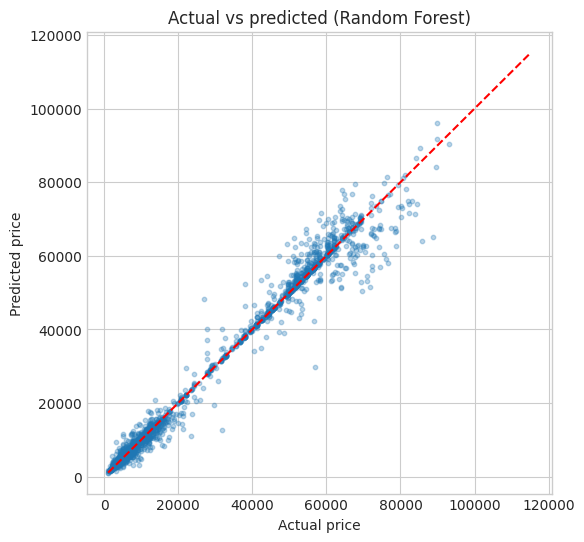

Best model: Random Forest


In [60]:
best = results.iloc[0]['Model']
idx = np.random.RandomState(0).choice(len(y_test), size=min(3000, len(y_test)), replace=False)
plt.figure(figsize=(6, 6))
plt.scatter(y_test.iloc[idx], preds[best][idx], alpha=.3, s=10)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, color='red', linestyle='--')
plt.xlabel('Actual price'); plt.ylabel('Predicted price'); plt.title(f'Actual vs predicted ({best})'); plt.show()
print('Best model:', best)

**Insight:** Random Forest is the best model with the lowest errors (MAE about Rs 1,104 and RMSE about Rs 2,716) and an R2 of about 0.99, so it explains roughly 99% of the variation in fares. Hist Gradient Boosting comes next (R2 about 0.97, MAE about Rs 2,156) and Linear Regression is the weakest (R2 about 0.91, MAE about Rs 4,501). This shows that fares depend on non-linear interactions (class, booking window, duration) that a straight-line model cannot capture. The feature importance agrees with the EDA: travel_class dominates (about 0.88), followed by duration (about 0.06) and days_left (about 0.02), while airline and city features add very little.

## Conclusion
Answers to the key analytical questions (from the EDA above):

1. **Highest/lowest fares:** Vistara has the highest median fare (Rs 15,543) and AirAsia the lowest (Rs 3,276). Chennai-Bangalore is the costliest route (median Rs 10,469) and Delhi-Hyderabad the cheapest (Rs 6,109).
2. **Booking closer to departure:** Yes. The median fare in the last 3 days (Rs 16,572) is 181% higher than for bookings 46-60 days ahead; Economy rises 193%, Business only 11.6%. The biggest drop happens at about 15 days.
3. **Stops:** Non-stop flights are cheapest (median Rs 4,499) versus one-stop (Rs 7,959) and two or more stops (Rs 8,307).
4. **Longer flights:** Only slightly more expensive (Pearson 0.20, Spearman 0.32); within the same route and class the link stays weak.
5. **Departure time:** Morning departures have the highest median fare (Rs 8,112) and Late Night the lowest (Rs 4,499).
6. **Economy vs Business:** Business median fare (Rs 53,164) is about 9 times Economy (Rs 5,772); only Vistara and Air India sell Business class.
7. **Strongest association with price:** Travel class by far, followed by duration and days left.
8. **Prediction:** Random Forest predicts fares best (R2 about 0.99, MAE about Rs 1,104), ahead of Hist Gradient Boosting (R2 about 0.97) and Linear Regression (R2 about 0.91). Travel class is by far the most important feature.
9. **Advice for travellers:** Book at least 16 days ahead, prefer low-cost airlines in Economy, choose non-stop flights where possible and consider late-night or afternoon departures.

**Limitations:** The data looks like sampled booking options, not the full flight schedule, and covers only 6 airlines and 6 metro cities. Fares are for one snapshot of time, so seasonality and festivals are not captured. The models were tested on a random split, so near-identical tickets can appear in both train and test sets; accuracy on completely unseen flights may be lower.

**Future work:** Hyper-parameter tuning, log-transforming the price, adding seasonal and holiday features, and deploying the best model as a simple fare-prediction app.